# AICS-202 | Laboratory 04
## Defensive Retraining and Robustness Assessment
Course module: 4 | Suggested duration: 5 hours

**Objective:** compare a baseline model with a model trained using simple augmented adversarial samples. Independently evaluate both models with FGSM and a small PGD variant.

**Important:** augmentation is not a guarantee of robustness; attacks must be adapted to the defended model to avoid misleading results.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
digits = load_digits()
X = digits.data.astype(float) / 16.0
y = digits.target.astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)

def build_model(train_features, train_labels):
    model = LogisticRegression(max_iter=600, random_state=SEED)
    model.fit(train_features, train_labels)
    return model

model = build_model(X_train, y_train)
print('Dataset:', X.shape, '| Train:', len(X_train), '| Test:', len(X_test))
print('Clean test accuracy:', round(accuracy_score(y_test, model.predict(X_test)), 4))

Dataset: (1797, 64) | Train: 1347 | Test: 450
Clean test accuracy: 0.9622


In [10]:
def input_loss_gradient(model, features, labels):
    """Cross-entropy gradient with respect to input, for multinomial logistic regression."""
    probs = model.predict_proba(features)
    targets = np.zeros_like(probs)
    label_indices = np.searchsorted(model.classes_, labels)
    targets[np.arange(len(labels)), label_indices] = 1.0
    return (probs - targets) @ model.coef_

def fgsm(model, features, labels, epsilon=0.10):
    grad = input_loss_gradient(model, features, labels)
    return np.clip(features + epsilon * np.sign(grad), 0.0, 1.0)

In [11]:
def pgd(model, features, labels, epsilon=0.12, alpha=0.03, steps=7, seed=42):
    rng = np.random.default_rng(seed)
    original = features.copy()
    perturbed = np.clip(original + rng.uniform(-epsilon, epsilon, size=original.shape), 0, 1)
    for _ in range(steps):
        grad = input_loss_gradient(model, perturbed, labels)
        perturbed = perturbed + alpha * np.sign(grad)
        perturbed = np.maximum(np.minimum(perturbed, original + epsilon), original - epsilon)
        perturbed = np.clip(perturbed, 0.0, 1.0)
    return perturbed

Baseline: clean=0.962 | FGSM=0.516 | PGD=0.489
Augmented training: clean=0.940 | FGSM=0.284 | PGD=0.260


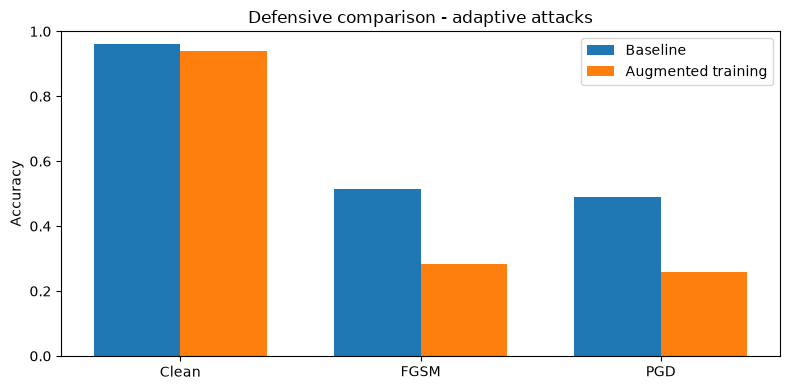

In [4]:
train_adversarial = fgsm(model, X_train, y_train, epsilon=0.10)
aug_features = np.concatenate([X_train, train_adversarial])
aug_labels = np.concatenate([y_train, y_train])
defended = build_model(aug_features, aug_labels)

def evaluate(model_to_test, label):
    clean = accuracy_score(y_test, model_to_test.predict(X_test))
    test_fgsm = fgsm(model_to_test, X_test, y_test, epsilon=0.12)
    test_pgd = pgd(model_to_test, X_test, y_test, epsilon=0.12, alpha=0.03, steps=7)
    fgsm_acc = accuracy_score(y_test, model_to_test.predict(test_fgsm))
    pgd_acc = accuracy_score(y_test, model_to_test.predict(test_pgd))
    print(f'{label}: clean={clean:.3f} | FGSM={fgsm_acc:.3f} | PGD={pgd_acc:.3f}')
    return [clean, fgsm_acc, pgd_acc]
base_results = evaluate(model, 'Baseline')
def_results = evaluate(defended, 'Augmented training')
ind = np.arange(3)
fig, ax = plt.subplots(figsize=(8,4))
ax.bar(ind-.18, base_results, width=.36, label='Baseline')
ax.bar(ind+.18, def_results, width=.36, label='Augmented training')
ax.set_xticks(ind, ['Clean', 'FGSM', 'PGD']); ax.set_ylim(0,1)
ax.set_ylabel('Accuracy'); ax.set_title('Defensive comparison - adaptive attacks')
ax.legend(); plt.tight_layout();plt.show()

In [5]:
def scores(m):
    clean = accuracy_score(y_test, m.predict(X_test))
    f = accuracy_score(y_test, m.predict(fgsm(m, X_test, y_test, epsilon=0.12)))
    p = accuracy_score(y_test, m.predict(pgd(m, X_test, y_test, epsilon=0.12, alpha=0.03, steps=7)))
    return clean, f, p

def transfer_acc(m):   # attack crafted against the BASELINE, tested on m
    return accuracy_score(y_test, m.predict(fgsm(model, X_test, y_test, epsilon=0.12)))

configs = [('Baseline (C=1)', model)]
for e in [0.03, 0.05, 0.07, 0.10]:
    adv = fgsm(model, X_train, y_train, epsilon=e)
    m = build_model(np.concatenate([X_train, adv]), np.concatenate([y_train, y_train]))
    configs.append((f'Aug eps={e:.2f}', m))

rows = []
print(f"{'configuration':<18}{'clean':>7}{'FGSM':>7}{'PGD':>7}{'transfer':>9}{'L1 weights':>11}")
for name, m in configs:
    c, f, p = scores(m); t = transfer_acc(m); l1 = float(np.abs(m.coef_).sum())
    rows.append((name, c, f, p, t, l1))
    print(f"{name:<18}{c:7.3f}{f:7.3f}{p:7.3f}{t:9.3f}{l1:11.1f}")

configuration       clean   FGSM    PGD transfer L1 weights
Baseline (C=1)      0.962  0.516  0.489    0.516      287.0
Aug eps=0.03        0.962  0.467  0.438    0.580      366.8
Aug eps=0.05        0.958  0.433  0.402    0.702      388.5
Aug eps=0.07        0.953  0.373  0.340    0.789      412.2
Aug eps=0.10        0.940  0.284  0.260    0.860      445.1


### Final practical evidence and risk conclusion
1. Compare clean-test and attacked-test accuracy for both models.
2. Explain why defensive effectiveness must be tested against the defended model itself.
3. Identify three limitations of this small dataset and short attack budget.
4. Produce a one-page robustness decision memo: deploy, improve or reject, with a rationale.

**Deliverables:** comparison chart, numeric results, limitations and decision memo. This is a local learning exercise, not a certification of model security.

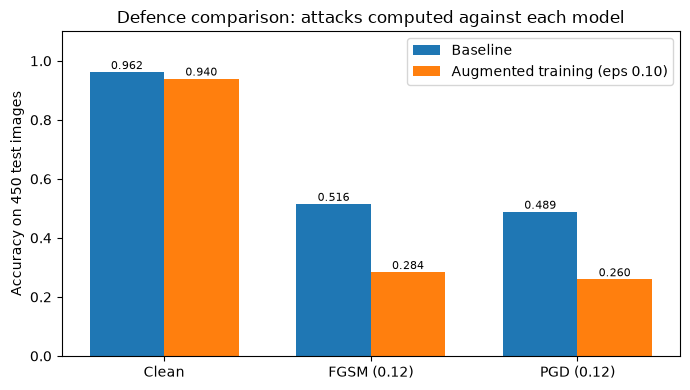

In [6]:
import os, csv
os.makedirs('../results', exist_ok=True)

with open('../results/E04_defence_comparison.csv', 'w', newline='') as fh:
    w = csv.writer(fh)
    w.writerow(['model', 'clean', 'fgsm_eps0.12', 'pgd_eps0.12'])
    w.writerow(['Baseline'] + [round(v, 4) for v in base_results])
    w.writerow(['Augmented (eps 0.10)'] + [round(v, 4) for v in def_results])

ind = np.arange(3)
fig, ax = plt.subplots(figsize=(7, 4))
b1 = ax.bar(ind - .18, base_results, width=.36, label='Baseline')
b2 = ax.bar(ind + .18, def_results, width=.36, label='Augmented training (eps 0.10)')
for bars in (b1, b2):
    for r in bars:
        ax.text(r.get_x() + r.get_width()/2, r.get_height() + 0.01,
                f'{r.get_height():.3f}', ha='center', fontsize=8)
ax.set_xticks(ind); ax.set_xticklabels(['Clean', 'FGSM (0.12)', 'PGD (0.12)'])
ax.set_ylim(0, 1.1); ax.set_ylabel('Accuracy on 450 test images')
ax.set_title('Defence comparison: attacks computed against each model')
ax.legend(); plt.tight_layout()
plt.savefig('../results/E04_defence_comparison.png', dpi=200)
plt.show()

In [7]:
def scores(m):
    clean = accuracy_score(y_test, m.predict(X_test))
    f = accuracy_score(y_test, m.predict(fgsm(m, X_test, y_test, epsilon=0.12)))
    p = accuracy_score(y_test, m.predict(pgd(m, X_test, y_test, epsilon=0.12, alpha=0.03, steps=7)))
    return clean, f, p

def transfer_acc(m):   # attack crafted against the BASELINE, tested on m
    return accuracy_score(y_test, m.predict(fgsm(model, X_test, y_test, epsilon=0.12)))

configs = [('Baseline (C=1)', model)]
for e in [0.03, 0.05, 0.07, 0.10]:
    adv = fgsm(model, X_train, y_train, epsilon=e)
    m = build_model(np.concatenate([X_train, adv]), np.concatenate([y_train, y_train]))
    configs.append((f'Aug eps={e:.2f}', m))

rows = []
print(f"{'configuration':<18}{'clean':>7}{'FGSM':>7}{'PGD':>7}{'transfer':>9}{'L1 weights':>11}")
for name, m in configs:
    c, f, p = scores(m); t = transfer_acc(m); l1 = float(np.abs(m.coef_).sum())
    rows.append((name, c, f, p, t, l1))
    print(f"{name:<18}{c:7.3f}{f:7.3f}{p:7.3f}{t:9.3f}{l1:11.1f}")

configuration       clean   FGSM    PGD transfer L1 weights
Baseline (C=1)      0.962  0.516  0.489    0.516      287.0
Aug eps=0.03        0.962  0.467  0.438    0.580      366.8
Aug eps=0.05        0.958  0.433  0.402    0.702      388.5
Aug eps=0.07        0.953  0.373  0.340    0.789      412.2
Aug eps=0.10        0.940  0.284  0.260    0.860      445.1


In [8]:
for c_val in [0.1, 0.3]:
    m = LogisticRegression(max_iter=600, random_state=SEED, C=c_val).fit(X_train, y_train)
    c, f, p = scores(m); t = transfer_acc(m); l1 = float(np.abs(m.coef_).sum())
    name = f'Baseline, C={c_val}'
    rows.append((name, c, f, p, t, l1))
    print(f"{name:<18}{c:7.3f}{f:7.3f}{p:7.3f}{t:9.3f}{l1:11.1f}")

with open('../results/E04_improvement_study.csv', 'w', newline='') as fh:
    w = csv.writer(fh)
    w.writerow(['configuration', 'clean', 'fgsm_adaptive', 'pgd_adaptive',
                'fgsm_transfer_from_baseline', 'l1_weight_norm'])
    for r in rows:
        w.writerow([r[0]] + [round(v, 4) for v in r[1:]])

Baseline, C=0.1     0.938  0.627  0.627    0.627      150.5
Baseline, C=0.3     0.956  0.591  0.576    0.587      206.4
